# CLI and terminals

Every method is a subcommand, its params are options. `amoorion` alone in a terminal
asks step by step. `main` takes the same arguments as the command line.

In [1]:
from amoorion import Amoorion

# A sandbox for this whole notebook: secrets only from variables, the inbox and
# the dataset in a temporary folder. Nothing here can touch your real setup.
Amoorion.init()

PosixPath('/tmp/amoorion-ruu3v403')

In [2]:
# The function behind the `amoorion` command; it takes what the shell would pass.
from amoorion.cli import main

# As a table for people: `amoorion plugins`.
main(["plugins"])

┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ name            ┃ description                                     ┃ capabilities                        ┃ error ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ blogger         │ Blogger by mail: post                           │ ["post"]                            │       │
│ bluesky         │ Bluesky (AT Protocol): post, read, reply,       │ ["delete", "post", "read", "reply"] │       │
│                 │ delete                                          │                                     │       │
│ discord         │ Discord bot in one channel (REST API): post,    │ ["delete", "post", "read", "reply"] │       │
│                 │ read, reply, delete                             │                                     │       │
│ discord-webhook │ Discord channel webhook, no bot: post, delete   │ ["delete", "post"]                  │       │
│                 │ what it posted                                  │                                     │       │
│ dryrun          │ sends nothing; remembers posts for the running  │ ["delete", "post", "read", "reply"] │       │
│                 │ process                                         │                                     │       │
│ email           │ E-mail: send by SMTP, read by IMAP, reply       │ ["post", "read", "reply"]           │       │
│ facebook        │ Facebook Page (Graph API): post, read, reply as │ ["delete", "post", "read", "reply"] │       │
│                 │ comment, delete                                 │                                     │       │
│ mastodon        │ Mastodon (REST API): post, read, reply, delete  │ ["delete", "post", "read", "reply"] │       │
│ matrix          │ Matrix room (client-server API): post, read,    │ ["delete", "post", "read", "reply"] │       │
│                 │ reply, delete (redact)                          │                                     │       │
│ ntfy            │ ntfy: push notifications to one topic, and read │ ["post", "read"]                    │       │
│                 │ them                                            │                                     │       │
│ telegram        │ Telegram bot in one chat (Bot API): post, read, │ ["delete", "post", "read", "reply"] │       │
│                 │ reply, delete                                   │                                     │       │
│ tumblr          │ Tumblr API v2: post, read, delete               │ ["delete", "post", "read"]          │       │
│ x               │ X (twitter) API v2: post, read, reply, delete   │ ["delete", "post", "read", "reply"] │       │
└─────────────────┴─────────────────────────────────────────────────┴─────────────────────────────────────┴───────┘

0

The same in a notebook, with pandas: the methods answer plain data, so nothing here depends on the terminal.


In [3]:
import pandas as pd

from amoorion import Amoorion

amo = Amoorion()

pd.DataFrame(amo.plugins())[["name", "description", "capabilities"]]

,name,description,capabilities
0,blogger,Blogger by mail: post,[post]
1,bluesky,"Bluesky (AT Protocol): post, read, reply, delete","[delete, post, read, reply]"
2,discord,"Discord bot in one channel (REST API): post, r...","[delete, post, read, reply]"
3,discord-webhook,"Discord channel webhook, no bot: post, delete ...","[delete, post]"
4,dryrun,sends nothing; remembers posts for the running...,"[delete, post, read, reply]"
5,email,"E-mail: send by SMTP, read by IMAP, reply","[post, read, reply]"
6,facebook,"Facebook Page (Graph API): post, read, reply a...","[delete, post, read, reply]"
7,mastodon,"Mastodon (REST API): post, read, reply, delete","[delete, post, read, reply]"
8,matrix,"Matrix room (client-server API): post, read, r...","[delete, post, read, reply]"
9,ntfy,"ntfy: push notifications to one topic, and rea...","[post, read]"


In [4]:
# `--json` comes before the method, and gives output for scripts.
main(
    [
        "--json",
        "publish",
        "--title",
        "Hi",
        "--text",
        "from the CLI",
        "--to",
        "dryrun",
    ]
)

[
  {
    "platform": "dryrun",
    "ok": true,
    "message": {
      "platform": "dryrun",
      "text": "Hi\n\nfrom the CLI",
      "id": "1",
      "url": null,
      "author": null,
      "reply_to": null,
      "created_at": "2026-10-31T07:54:58.084032Z"
    },
    "error": null
  }
]


0

The JSON of a command, as a table, and what the platforms can do, as a plot:


  platform    ok  message.text
0   dryrun  True  from the CLI


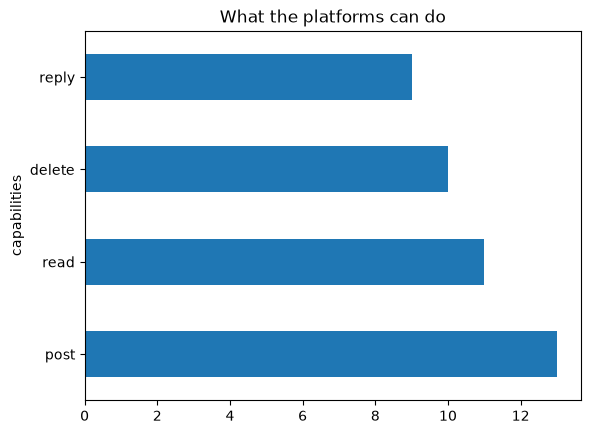

In [5]:
import json

import contextlib

import io

import matplotlib.pyplot as plt

# `--json` printed text; caught here, it is data.
caught = io.StringIO()

with contextlib.redirect_stdout(caught):
    main(
        [
            "--json",
            "publish",
            "--text",
            "from the CLI",
            "--to",
            "dryrun",
        ]
    )

print(
    pd.json_normalize(json.loads(caught.getvalue()))[
        ["platform", "ok", "message.text"]
    ]
)

# How many platforms can do what.
pd.DataFrame(amo.plugins()).explode("capabilities")[
    "capabilities"
].value_counts().plot.barh(title="What the platforms can do")

plt.show()

In [6]:
# Finding nothing is no error: an empty list.
main(
    [
        "--json",
        "search",
        "--text",
        "nothing yet",
    ]
)

[]


0

An error is a line and an exit code, no traceback:

In [7]:
# A wrong platform: one line of error and exit code 1, no traceback.
main(
    [
        "read",
        "--platform",
        "nowhere",
    ]
)

amoorion: no plugin named 'nowhere'


1

A command line can also be one Python expression. `/` names a command, `-` an option, `+` a value, and `>>` runs it and hands over the output:


In [8]:
# Printed, as `main` above printed it.
amo.CALL() / "read" - "platform" + "nowhere" >> print

# Or kept: anything taking the text will do.
output = []

call = amo.CALL() / "--json" / "plugins" >> output.append

# The exit code stays on the call.
call.code, output[0][:60]

amoorion: no plugin named 'nowhere'



(0, '[\n  {\n    "name": "blogger",\n    "description": "Blogger by ')

From a shell:

```sh
uv run amoorion publish --text "hello" --to dryrun
uv run amoorion --json inbox | jq '.[].text'
uv run amoorion          # asks what to do
```

Everything also runs on a setup of your own, `Amoorion("my.env").cli("inbox")`.